## **random forest regression, decision tree regression and support vector regression**

In [1]:
from google.colab import files
import pandas as pd

filename = 'lung_cancer_dataset_final.csv'

uploaded = files.upload()
df = pd.read_csv(filename)
df.head()

Saving lung_cancer_dataset_final.csv to lung_cancer_dataset_final.csv


,Patient_ID,Diagnosis_Year,Diagnosis_Date,WHO_Region,Country,Age,Age_Group,Gender,Smoking_Status,Cigarettes_Per_Day,...,Symptom_Count,Cancer_Type,NSCLC_Subtype,Cancer_Stage,Tumor_Size_cm,Metastasis,Diagnosis_Method,Treatment,Survival_Months,Survived
0,LC-0003,2017,2017-04-05,Western Pacific,Japan,53,50-59,Female,Never Smoked,0,...,3,NSCLC,Squamous Cell,Stage I,2.9,No,LDCT Screening,Surgery,69,No
1,LC-0007,2026,2026-02-08,Eastern Mediterranean,Qatar,85,80-89,Female,Never Smoked,0,...,0,NSCLC,Large Cell,Stage III,3.8,No,Biopsy,Chemotherapy,18,No
2,LC-0011,2025,2025-10-09,Africa,Nigeria,51,50-59,Female,Never Smoked,0,...,2,NSCLC,Adenocarcinoma,Stage IV,6.7,Yes,PET Scan,Chemotherapy,9,No
3,LC-0013,2022,2022-06-09,Europe,France,57,50-59,Female,Current Smoker,14,...,4,NSCLC,Squamous Cell,Stage III,7.0,No,Biopsy,Immunotherapy,17,No
4,LC-0016,2026,2026-01-12,South-East Asia,Sri Lanka,58,50-59,Male,Never Smoked,0,...,7,NSCLC,Adenocarcinoma,Stage I,1.4,No,LDCT Screening,Surgery,50,Yes


In [2]:
import numpy as np
from sklearn.preprocessing import LabelEncoder

df_model = df.copy()

# Drop identifier / free-text columns not useful as model features
drop_cols = ['Patient_ID', 'Diagnosis_Date']
df_model = df_model.drop(columns=[c for c in drop_cols if c in df_model.columns])

# Label-encode all remaining categorical (object/string) columns
cat_cols = df_model.select_dtypes(include='object').columns.tolist()
encoders = {}
for c in cat_cols:
    le = LabelEncoder()
    df_model[c] = le.fit_transform(df_model[c].astype(str))
    encoders[c] = le

df_model.head()

,Diagnosis_Year,WHO_Region,Country,Age,Age_Group,Gender,Smoking_Status,Cigarettes_Per_Day,Years_Smoking,Pack_Years,...,Symptom_Count,Cancer_Type,NSCLC_Subtype,Cancer_Stage,Tumor_Size_cm,Metastasis,Diagnosis_Method,Treatment,Survival_Months,Survived
0,2017,5,21,53,2,0,2,0,0,0.0,...,3,0,3,0,2.9,0,4,5,69,0
1,2026,2,41,85,5,0,2,0,0,0.0,...,0,0,1,2,3.8,0,0,1,18,0
2,2025,0,35,51,2,0,2,0,0,0.0,...,2,0,0,3,6.7,1,6,1,9,0
3,2022,3,13,57,2,0,0,14,20,14.0,...,4,0,3,2,7.0,0,0,2,17,0
4,2026,4,48,58,2,1,2,0,0,0.0,...,7,0,0,0,1.4,0,4,5,50,1


In [3]:
target = 'Survival_Months'
X = df_model.drop(columns=[target])
y = df_model[target]

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

Feature matrix shape: (1000, 43)
Target shape: (1000,)


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train size:", X_train.shape[0], " Test size:", X_test.shape[0])

Train size: 800  Test size: 200


In [5]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR

# --- Random Forest Regression ---
rf_model = RandomForestRegressor(n_estimators=200, random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

# --- Decision Tree Regression ---
dt_model = DecisionTreeRegressor(random_state=42)
dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

# --- Support Vector Regression ---
svr_model = SVR(kernel='rbf', C=100, epsilon=0.5)
svr_model.fit(X_train_scaled, y_train)  # SVR: use scaled data
svr_pred = svr_model.predict(X_test_scaled)

print("All three models trained.")


All three models trained.


In [8]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
def evaluate(name, y_true, y_pred):
    r2 = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    return {"Model": name, "R2 Score": round(r2, 4), "MAE": round(mae, 3), "RMSE": round(rmse, 3)}

results = [
    evaluate("Random Forest Regression", y_test, rf_pred),
    evaluate("Decision Tree Regression", y_test, dt_pred),
    evaluate("Support Vector Regression", y_test, svr_pred),
]

results_df = pd.DataFrame(results)
results_df

,Model,R2 Score,MAE,RMSE
0,Random Forest Regression,0.7734,8.450,11.291
1,Decision Tree Regression,0.5330,11.525,16.208
2,Support Vector Regression,0.6920,9.721,13.163


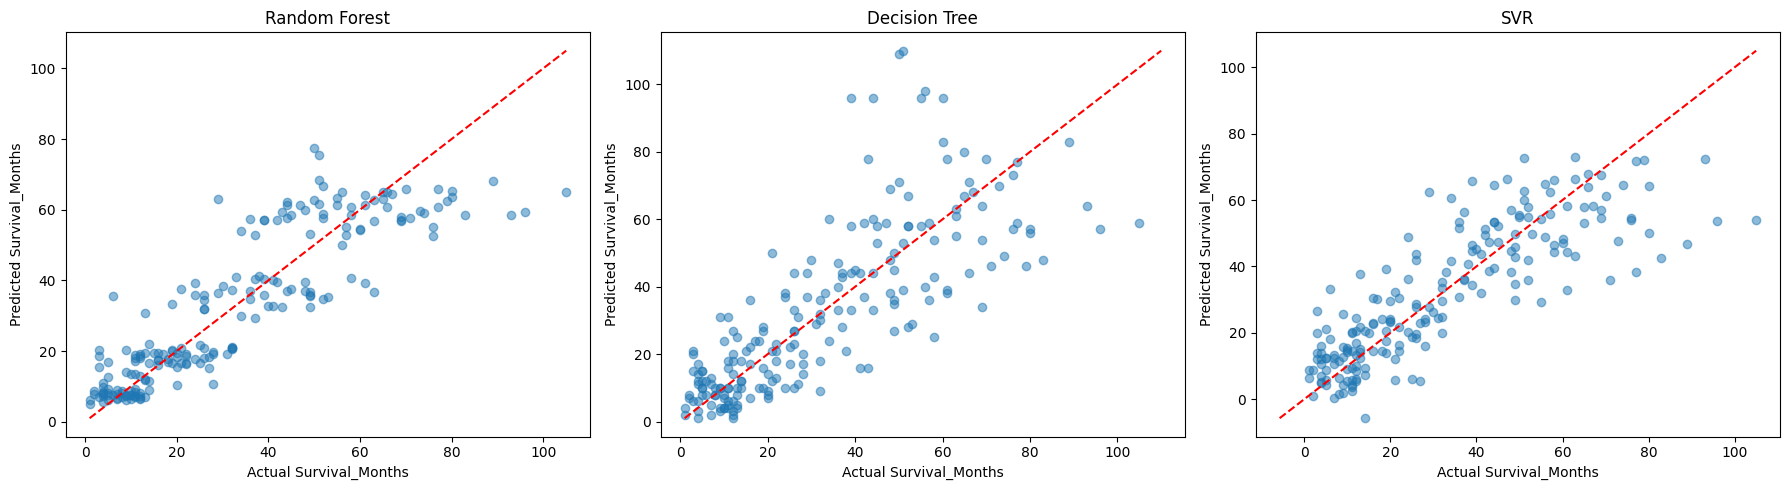

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
preds = [("Random Forest", rf_pred), ("Decision Tree", dt_pred), ("SVR", svr_pred)]

for ax, (name, pred) in zip(axes, preds):
    ax.scatter(y_test, pred, alpha=0.5)
    lims = [min(y_test.min(), pred.min()), max(y_test.max(), pred.max())]
    ax.plot(lims, lims, 'r--')
    ax.set_xlabel("Actual Survival_Months")
    ax.set_ylabel("Predicted Survival_Months")
    ax.set_title(name)

plt.tight_layout()
plt.show()